# Bassez et al. 2021 — Breast Cancer (10x)

**04 — EMT-TF expression (unconditional).** Categorical overlay of thresholded EMT-TF expressers on a grey manifold. Panel spans Snail/Zeb/Twist **and** FOXC/PRRX families; gene selection gated on detectable expression; VIM excluded (mesenchymal marker, not a TF).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
body = adata[adata.obs['t'].notna()].copy()
t = body.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('Body cells:', body.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

Body cells: 65837 | pseudotime 0.0 -> 17.87


### Derive the informative EMT-TFs
Score each candidate on the Body by detection fraction and pseudotime trend; keep factors above a 3% detection floor. Pick the strongest root-trending (most negative rho) and terminus-trending (most positive rho) TF; if none is terminus-enriched, report the two most root/origin-concentrated factors.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
X = body[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x=X[:,j]; rho,p=spearmanr(tn,x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.rho_vs_t < 0,'root','terminus')
df = df.sort_values('rho_vs_t'); print(df.to_string(index=False))
FLOOR = 0.03
ok = df[df.frac_expr > FLOOR]
root_tfs = ok[ok.rho_vs_t < 0].sort_values('rho_vs_t')
term_tfs = ok[ok.rho_vs_t > 0].sort_values('rho_vs_t')
if len(root_tfs) > 0 and len(term_tfs) > 0:
    tf_a = root_tfs.iloc[0]['TF']; tf_b = term_tfs.iloc[-1]['TF']
    label_a, label_b = f'{tf_a} (root)', f'{tf_b} (terminus)'
    print(f'\nderived pair: {tf_a} (root/origin) <-> {tf_b} (terminus)')
else:
    ok2 = ok.sort_values('frac_expr', ascending=False)
    tf_a = ok2.iloc[0]['TF']; tf_b = ok2.iloc[1]['TF']
    label_a, label_b = f'{tf_a} (most expressed)', f'{tf_b} (2nd most expressed)'
    print(f'\nno root/terminus split among detected EMT-TFs; showing two most broadly expressed: {tf_a}, {tf_b}')

    TF  frac_expr  mean_early  mean_late  rho_vs_t      end
 FOXC1      0.024       0.016      0.002    -0.104     root
 SNAI1      0.027       0.019      0.005    -0.082     root
  ZEB2      0.177       0.145      0.109    -0.071     root
 FOXC2      0.012       0.005      0.003    -0.032     root
 SNAI2      0.086       0.023      0.010    -0.001     root
 PRRX2      0.032       0.003      0.001     0.014 terminus
TWIST2      0.042       0.002      0.001     0.025 terminus
TWIST1      0.029       0.001      0.001     0.028 terminus
  ZEB1      0.135       0.050      0.076     0.052 terminus
 PRRX1      0.138       0.013      0.035     0.073 terminus

derived pair: ZEB2 (root/origin) <-> PRRX1 (terminus)


### Figure — EMT-TF expression overlay (`expression.pdf`)
Grey manifold with the two derived TFs overlaid as thresholded categorical expressers (upper quartile among expressers).

overlay thresholds (upper quartile among expressers): {'ZEB2': 0.922, 'PRRX1': 1.117} | cells shown: {'ZEB2': 2914, 'PRRX1': 2271}
ZEB2: 17.7% expressing; 2914 shown
PRRX1: 13.8% expressing; 2271 shown
saved expression.pdf


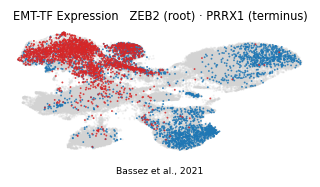

In [5]:
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr={}
for g in [tf_a,tf_b]:
    v=_vec(g); pos=v[v>0]; thr[g]=float(np.quantile(pos,0.75)) if pos.size else 0.0
sel={g:_vec(g)>thr[g] for g in [tf_a,tf_b]}
print('overlay thresholds (upper quartile among expressers):', {g:round(thr[g],3) for g in [tf_a,tf_b]},
      '| cells shown:', {g:int(sel[g].sum()) for g in [tf_a,tf_b]})
xl = adata.obsm['X_umap']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
order=sorted([tf_a,tf_b], key=lambda g:-int(sel[g].sum()))
colors={tf_a:'tab:blue', tf_b:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=6, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap=adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=6, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {label_a} · {label_b}', size=7.5)
ax.text(.5,-.14,'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [tf_a,tf_b]:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown')
print('saved expression.pdf')